<a href="https://colab.research.google.com/github/tisha-gupta/DL_Learnings/blob/ANN/customer_churn_pred_binary_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Goal: To predict whether the customer will leave the bank or not

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Churn_Modelling.csv.xls")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
print(df.shape)

(10000, 14)


In [5]:
#checking for missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
#checking for duplicate rows
df.duplicated().sum()

np.int64(0)

In [7]:
#how many people exited the bank(left the bank)
df['Exited'].value_counts()

,count
Exited,
0,7963
1,2037


In [8]:
#different places people are from
df['Geography'].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [9]:
#different types of gender in data and their counts to know data is skewed with respect to
#gender or not
df['Gender'].value_counts()

,count
Gender,
Male,5457
Female,4543


In [10]:
#dropping columns that does not seems to be useful
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace = True)

In [11]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [12]:
#turning 2 categorical columns to one hot encoded columns
df = pd.get_dummies(df, columns = ['Geography', 'Gender'], drop_first = True)

In [13]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [14]:
X = df.drop(columns = ['Exited'])
y = df['Exited']

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [16]:
X_train.shape

(8000, 11)

In [17]:
from sklearn.preprocessing import StandardScaler

In [18]:
#Now we are scaling the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
X_test_scaled

array([[-1.03768121,  0.77498705, -1.0482813 , ..., -0.58312392,
        -0.57273139,  0.91509065],
       [ 0.30708683, -0.46686456, -0.70174202, ..., -0.58312392,
        -0.57273139,  0.91509065],
       [-1.23422423,  0.29735181, -1.0482813 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       ...,
       [-0.86182692, -0.46686456,  1.72403288, ..., -0.58312392,
         1.74601919,  0.91509065],
       [-0.30323097, -0.84897275, -1.0482813 , ...,  1.71490137,
        -0.57273139, -1.09278791],
       [ 0.04847759,  1.25262228,  1.3774936 , ...,  1.71490137,
        -0.57273139,  0.91509065]])

In [20]:
X_train_scaled

array([[-0.23082038, -0.94449979, -0.70174202, ...,  1.71490137,
        -0.57273139,  0.91509065],
       [-0.25150912, -0.94449979, -0.35520275, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [-0.3963303 ,  0.77498705,  0.33787579, ...,  1.71490137,
        -0.57273139, -1.09278791],
       ...,
       [ 0.22433188,  0.58393295,  1.3774936 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 0.13123255,  0.01077067,  1.03095433, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 1.1656695 ,  0.29735181,  0.33787579, ...,  1.71490137,
        -0.57273139,  0.91509065]])

In [21]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [22]:
model = Sequential()
model.add(Dense(3, activation = 'sigmoid', input_dim = 11))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
#binary_crossentropy(log loss) -> because here we are performaing binary classification
#adam -> gradient descent
model.compile(loss='binary_crossentropy', optimizer = 'adam')

In [25]:
model.fit(X_train_scaled, y_train, epochs = 10)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.6367
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5204
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4758
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4564
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4456
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.4385
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4335
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4298
Epoch 9/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4270
Epoch 10/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4249


In [26]:
model.layers[0].get_weights()
#1st hidden layer weights and biases

[array([[-0.33569506,  0.08499995, -0.28568786],
        [ 0.40572536, -2.0041192 , -1.0752748 ],
        [-0.30365682, -0.08856296,  0.2851571 ],
        [ 0.52772844, -0.01809031, -0.67342484],
        [-0.67719376,  0.01888599, -0.25126547],
        [ 0.19230418,  0.1382829 , -0.02714574],
        [-1.2939804 ,  0.37464434,  0.76665175],
        [-0.42718646, -0.1647426 , -0.28996512],
        [ 0.18827768, -0.6803252 , -0.5288511 ],
        [ 0.17684586,  0.02955052,  0.09319844],
        [-0.785536  ,  0.36955926, -0.03282559]], dtype=float32),
 array([-0.5139278 ,  0.53202456,  0.17206286], dtype=float32)]

In [27]:
model.layers[1].get_weights()
#Output layer weights and biases

[array([[ 0.8069342],
        [-1.8613268],
        [-0.4778637]], dtype=float32),
 array([-0.55531245], dtype=float32)]

In [28]:
model.predict(X_test_scaled)
#We will get probabilities as we we are using sigmoid function in output layer

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[0.1329207 ],
       [0.14938451],
       [0.13986722],
       ...,
       [0.06602277],
       [0.1226925 ],
       [0.37483886]], dtype=float32)

In [29]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [30]:
import numpy as np

In [31]:
#As we want to binary classify the data we need to findout the threshold point
#like here we are using 0.5 or we can use Avg curve to find the best threshold point
y_pred = np.where(y_log>0.5, 1, 0)

In [32]:
from sklearn.metrics import accuracy_score

In [33]:
accuracy_score(y_test, y_pred)

0.8165

### Architecture changed with a few more things

In [34]:
model1 = Sequential()

In [35]:
model1.add(Dense(11, activation = 'relu', input_dim = 11))
model1.add(Dense(11, activation = 'relu'))
model1.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(loss='binary_crossentropy', optimizer = 'Adam', metrics = ['accuracy'])

In [38]:
history = model.fit(X_train_scaled, y_train, epochs = 100, validation_split = 0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8188 - loss: 0.4225 - val_accuracy: 0.8169 - val_loss: 0.4258
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8208 - loss: 0.4211 - val_accuracy: 0.8181 - val_loss: 0.4247
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8225 - loss: 0.4200 - val_accuracy: 0.8156 - val_loss: 0.4237
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8223 - loss: 0.4190 - val_accuracy: 0.8150 - val_loss: 0.4229
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8228 - loss: 0.4181 - val_accuracy: 0.8156 - val_loss: 0.4220
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8239 - loss: 0.4173 - val_accuracy: 0.8163 - val_loss: 0.4213
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8230 - loss: 0.4165 - val_accuracy: 0.8150 - val_loss: 0.4205
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8242 - loss: 0.4158 - val_accu

In [39]:
model1.layers[0].get_weights()

[array([[ 0.23481011, -0.35670483, -0.38391286, -0.37216562,  0.10471046,
         -0.517909  ,  0.10014755, -0.33557236,  0.41001952,  0.23133987,
         -0.41741964],
        [-0.27883923, -0.3469624 ,  0.03419346, -0.4203414 ,  0.47772098,
          0.03450686, -0.23820502,  0.11372036,  0.04734743,  0.36347646,
          0.31149364],
        [-0.33947563,  0.02753538, -0.2453906 ,  0.23061377, -0.4014165 ,
          0.12507617,  0.45850623, -0.49533492, -0.09311247,  0.34715438,
         -0.30104882],
        [ 0.45561945,  0.42860126,  0.3028316 ,  0.2535149 , -0.30586487,
          0.37846845,  0.14910114,  0.1539905 ,  0.1708253 , -0.44593954,
         -0.43061537],
        [ 0.37837768, -0.12316173,  0.45046473,  0.3266384 ,  0.05085748,
          0.13214076,  0.04899073, -0.4897163 ,  0.27025378, -0.09837863,
         -0.09316227],
        [-0.08962607, -0.46977526,  0.32663018,  0.15279734,  0.30773836,
          0.36352885, -0.11234516, -0.2613463 ,  0.21915907, -0.4106409

In [40]:
model1.layers[1].get_weights()

[array([[ 0.056768  , -0.21132553, -0.51472026,  0.4378733 , -0.16663739,
         -0.07036823, -0.3110745 , -0.26246354, -0.20240563,  0.44852638,
          0.5220714 ],
        [-0.1627818 , -0.02010363, -0.08074826,  0.3360359 ,  0.45347828,
         -0.02746952, -0.465937  , -0.03927943, -0.23708951,  0.17284298,
          0.51426095],
        [-0.36289695, -0.42771202,  0.37199903, -0.29844606, -0.11032188,
         -0.3720574 ,  0.49139804, -0.05664086,  0.47062606,  0.05719632,
         -0.0059278 ],
        [-0.411738  ,  0.51575416,  0.42842996, -0.1888867 ,  0.02441615,
         -0.26288226,  0.25448048,  0.5120501 , -0.2819495 , -0.32500732,
         -0.21055058],
        [ 0.23701978,  0.2528667 ,  0.50161976,  0.23554957,  0.11926913,
          0.5202915 ,  0.4870196 ,  0.30178392, -0.37472004, -0.28769115,
          0.41845185],
        [-0.16981637,  0.41159183,  0.33929396, -0.09618449, -0.2009069 ,
          0.26697755, -0.3531117 ,  0.4182768 ,  0.4206888 , -0.4153572

In [41]:
model1.layers[2].get_weights()

[array([[ 0.35556597],
        [-0.12957644],
        [ 0.59886354],
        [-0.12946129],
        [ 0.544439  ],
        [-0.5502866 ],
        [ 0.65359205],
        [ 0.22832799],
        [ 0.25714755],
        [-0.3826283 ],
        [-0.55563676]], dtype=float32),
 array([0.], dtype=float32)]

In [42]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [43]:
y_pred = np.where(y_log>0.5, 1, 0)

In [44]:
accuracy_score(y_test, y_pred)

0.85

In [45]:
import matplotlib.pyplot as plt

In [46]:
#history.history --> The history.history attribute in Keras is a standard Python dictionary that records the training loss values and metrics at successive epochs.

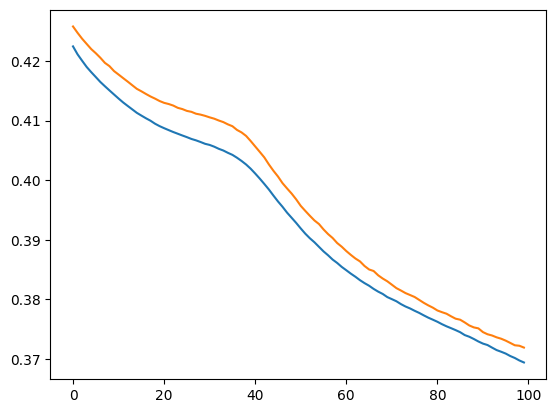

In [47]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

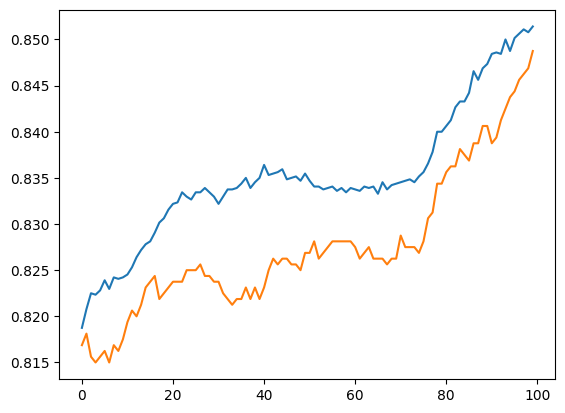

In [48]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

### We can see little overfitting is happening, we can use dropout or regularisation to improve our model